# Simulador de transmissão digital — demonstração

`ASCII → bits → código de linha → modulação → canal → demodulação → decodificação → BER`

Este notebook **só importa** o código do repositório (`src/sim/` e `experiments/`) e os resultados
em `results/`. Nenhuma lógica foi reescrita aqui.

**Código de linha não é correção de erros:** ele define como os bits viram sinal (transições,
sincronismo, componente DC). Este trabalho mede os erros que sobram depois da decodificação.

In [1]:
import json
import os
import sys
import time
from pathlib import Path

# Os scripts assumem a raiz do repositório como diretório de trabalho.
ROOT = Path.cwd()
if not (ROOT / "src" / "sim").exists():
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "experiments"))

import numpy as np
from IPython.display import Image, Markdown, display

import demo
import make_plots
from sim import channel, line_codes, modulation, source
from sim.link import run_link

text = source.load_source()
print(f"Mensagem: {len(text):,} caracteres ASCII -> {len(source.text_to_bits(text)):,} bits")

Mensagem: 12,533 caracteres ASCII -> 100,264 bits


## 1. A cadeia de transmissão, etapa por etapa

Uma palavra curta passando por cada módulo de `src/sim/`: Manchester + QPSK em AWGN a 4 dB.

In [2]:
msg = "Capitu"
code_name, mod_name, ebn0_db = "manchester", "qpsk", 4.0

bits = source.text_to_bits(msg)
chips = line_codes.encode(bits, code_name)
symbols = modulation.modulate(chips, mod_name)
eta = modulation.chips_per_symbol(mod_name) / line_codes.chips_per_bit(code_name)

rx_symbols = channel.transmit(symbols, ebn0_db, eta, "awgn", np.random.default_rng(5))
rx_chips = modulation.demodulate(rx_symbols, mod_name)
rx_bits, violations = line_codes.decode(rx_chips, code_name)

group = lambda b: " ".join("".join(map(str, b[i : i + 8])) for i in range(0, len(b), 8))
print(f"texto         : {msg!r}")
print(f"bits (8/char) : {group(bits)}")
print(f"chips         : {len(chips)} chips (Manchester: 2 por bit)")
print(f"símbolos QPSK : {len(symbols)} símbolos complexos, ex.: {np.round(symbols[:2], 3)}")
print(f"recebidos     : {np.round(rx_symbols[:2], 3)}  <- ruído a {ebn0_db:g} dB")
print(f"bits recebidos: {group(rx_bits)}")
print(f"erros de bit  : {int((bits != rx_bits).sum())}  | violações Manchester detectadas: {violations}")
print(f"texto recebido: {source.bits_to_text(rx_bits)!r}")

texto         : 'Capitu'
bits (8/char) : 01000011 01100001 01110000 01101001 01110100 01110101
chips         : 96 chips (Manchester: 2 por bit)
símbolos QPSK : 48 símbolos complexos, ex.: [ 0.707-0.707j -0.707+0.707j]
recebidos     : [ 0.349-0.811j -1.298+0.593j]  <- ruído a 4 dB
bits recebidos: 01000011 00100001 01110000 01101001 01110100 01110101
erros de bit  : 1  | violações Manchester detectadas: 1
texto recebido: 'C!pitu'


## 2. Implementação funcionando: `experiments/demo.py`

Primeiro o **teste ideal** (Eb/N0 infinito): as nove combinações de código de linha × modulação
devem recuperar o texto exatamente. Depois, a 20 dB, os dois canais e os **índices dos bits
incorretos**.

In [3]:
demo.main()

TESTE IDEAL (Eb/N0 = infinito)
nrz               bpsk : OK, BER=0
nrz               qpsk : OK, BER=0
nrz               16qam: OK, BER=0
manchester        bpsk : OK, BER=0
manchester        qpsk : OK, BER=0
manchester        16qam: OK, BER=0
diff_manchester   bpsk : OK, BER=0


diff_manchester   qpsk : OK, BER=0
diff_manchester   16qam: OK, BER=0

DEMONSTRAÇÃO A 20 dB
awgn  nrz               bpsk : erros=   0, BER=0, bits incorretos=[nenhum]
awgn  nrz               qpsk : erros=   0, BER=0, bits incorretos=[nenhum]
awgn  nrz               16qam: erros=   0, BER=0, bits incorretos=[nenhum]
awgn  manchester        bpsk : erros=   0, BER=0, bits incorretos=[nenhum]
awgn  manchester        qpsk : erros=   0, BER=0, bits incorretos=[nenhum]
awgn  manchester        16qam: erros=   0, BER=0, bits incorretos=[nenhum]


awgn  diff_manchester   bpsk : erros=   0, BER=0, bits incorretos=[nenhum]
awgn  diff_manchester   qpsk : erros=   0, BER=0, bits incorretos=[nenhum]
awgn  diff_manchester   16qam: erros=   0, BER=0, bits incorretos=[nenhum]
burst nrz               bpsk : erros=  71, BER=0.000708, bits incorretos=[2950,3172,3179,4354,4358,4376,4384,10305]


burst nrz               qpsk : erros=  62, BER=0.000618, bits incorretos=[761,9629,9636,18113,18123,18141,18154,18156]
burst nrz               16qam: erros= 137, BER=0.00137, bits incorretos=[9677,9684,9692,9718,42528,42536,62893,65563]
burst manchester        bpsk : erros= 166, BER=0.00166, bits incorretos=[774,782,2617,2619,2622,2623,2627,2632]
burst manchester        qpsk : erros= 142, BER=0.00142, bits incorretos=[2950,2955,3170,3172,3173,3179,4351,4354]
burst manchester        16qam: erros= 140, BER=0.0014, bits incorretos=[756,765,767,772,773,779,9630,9631]
burst diff_manchester   bpsk : erros= 289, BER=0.00288, bits incorretos=[775,780,782,784,786,2025,2616,2623]


burst diff_manchester   qpsk : erros= 247, BER=0.00246, bits incorretos=[2951,2956,2958,3170,3179,4356,4358,4362]
burst diff_manchester   16qam: erros= 300, BER=0.00299, bits incorretos=[756,757,761,765,769,778,779,9627]

Trecho original:
 I  Do titulo.  Uma noite destas, vindo da cidade para o Engenho Novo, encontrei no trem da Central um rapaz aqui do bairro, que eu conheco de vista e de chapeo.

Trecho recebido (16-QAM/rajadas/20 dB):
 I  Do titulo.  Uma noite destas, vindo da cidade para o Engenho Novo, encontrei no trem da Central um rapaz aqui do bairro, que eu conheco de vista e de chapeo.


Efeito prático das rajadas a 20 dB (NRZ + 16-QAM): quantos caracteres do livro chegam alterados.

In [4]:
for scenario in channel.SCENARIOS:
    result = run_link(text, "nrz", "16qam", scenario, 20.0, seed=0)
    changed = [i for i, (a, b) in enumerate(zip(text, result.recovered_text, strict=True)) if a != b]
    print(f"{scenario:5s}: {result.bit_errors:4d} bits errados -> {len(changed):4d} de {len(text):,} caracteres alterados")

first = changed[0]
window = slice(max(first - 30, 0), first + 50)
flat = lambda s: s.replace("\n", " ")
print(f"\nprimeiro erro no caractere {first} (rajadas):")
print("  original:", flat(text[window]))
print("  recebido:", flat(result.recovered_text[window]))

awgn :    0 bits errados ->    0 de 12,533 caracteres alterados
burst:  137 bits errados ->   91 de 12,533 caracteres alterados

primeiro erro no caractere 1209 (rajadas):
  original: inze dias commigo."--"Meu caro Dom Casmurro, nao cuide que o dispenso do theatro
  recebido: inze dias commigo."--"Meu caro$Lgm Aasmurro, nao cuide que o dispenso do theatro


## 3. Metodologia e reprodução dos 990 ensaios

Configuração registrada em `results/run_info.json` e, em seguida, **toda a varredura executada de
novo** com `run_link`, comparada linha a linha com `results/raw.csv`.

In [5]:
info = json.loads(Path("results/run_info.json").read_text(encoding="utf-8"))
print(f"bits por transmissão : {info['message_bits_per_run']:,}")
print(f"Eb/N0 (dB)           : {info['ebn0_db_values']}")
print(f"sementes             : {info['seeds']}")
print(f"códigos / modulações : {info['line_codes']} / {info['modulations']}")
print(f"canais               : {info['scenarios']}")
print(f"rajadas              : {info['burst']}")
print(f"ensaios registrados  : {info['raw_rows']}")

bits por transmissão : 100,264
Eb/N0 (dB)           : [0, 2, 4, 6, 8, 10, 12, 14, 16, 18, 20]
sementes             : [0, 1, 2, 3, 4]
códigos / modulações : ['nrz', 'manchester', 'diff_manchester'] / ['bpsk', 'qpsk', '16qam']
canais               : ['awgn', 'burst']
rajadas              : {'stationary_bad_fraction': 0.01, 'mean_burst_symbols': 20.0, 'bad_ebn0_db': 0.0}
ensaios registrados  : 990


In [6]:
rows = make_plots.read_rows()
saved = {
    (r["scenario"], r["line_code"], r["modulation"], int(r["ebn0_db"]), int(r["seed"])): (
        int(r["bit_errors"]),
        int(r["violations"]),
    )
    for r in rows
}

started = time.perf_counter()
trials = matches = 0
for scenario in info["scenarios"]:
    for line_code in info["line_codes"]:
        for modulation_name in info["modulations"]:
            for ebn0 in info["ebn0_db_values"]:
                for seed in info["seeds"]:
                    r = run_link(text, line_code, modulation_name, scenario, ebn0, seed)
                    trials += 1
                    matches += saved[(scenario, line_code, modulation_name, ebn0, seed)] == (
                        r.bit_errors,
                        r.violations,
                    )
            print(f"{scenario:5s} {line_code:17s} {modulation_name:5s}: {trials:3d} ensaios", flush=True)

print(f"\n{matches}/{trials} ensaios idênticos aos de results/raw.csv ({time.perf_counter() - started:.0f} s)")
assert trials == len(rows) == matches

awgn  nrz               bpsk :  55 ensaios


awgn  nrz               qpsk : 110 ensaios


awgn  nrz               16qam: 165 ensaios


awgn  manchester        bpsk : 220 ensaios


awgn  manchester        qpsk : 275 ensaios


awgn  manchester        16qam: 330 ensaios


... (9 outputs left out)

burst diff_manchester   bpsk : 880 ensaios


burst diff_manchester   qpsk : 935 ensaios


burst diff_manchester   16qam: 990 ensaios



990/990 ensaios idênticos aos de results/raw.csv (45 s)


## 4. Resultados

Médias de cinco sementes com IC de 95% (Student). Os números abaixo vêm de
`make_plots.aggregate`, a mesma função que gera as figuras.

In [7]:
stats, eta_by_pair = make_plots.aggregate(rows)

def ber(line_code, mod, scenario, snr):
    mean, half, _ = stats[(line_code, mod, scenario, snr)]
    return f"{mean:.2e} ± {half:.1e}"

print("AWGN, Eb/N0 = 10 dB")
print(f"  NRZ + BPSK   : BER {ber('nrz', 'bpsk', 'awgn', 10)}")
print(f"  NRZ + 16-QAM : BER {ber('nrz', '16qam', 'awgn', 10)}")
print("Rajadas, Eb/N0 = 20 dB (o ruído extra não some com mais potência)")
print(f"  NRZ + BPSK               : BER {ber('nrz', 'bpsk', 'burst', 20)}")
print(f"  Manchester dif. + 16-QAM : BER {ber('diff_manchester', '16qam', 'burst', 20)}")
zero_at_20 = all(v[0] == 0 for k, v in stats.items() if k[2] == "awgn" and k[3] == 20)
print("AWGN, Eb/N0 = 20 dB:", "BER média zero nas 9 combinações" if zero_at_20 else "há erros")

AWGN, Eb/N0 = 10 dB
  NRZ + BPSK   : BER 3.99e-06 ± 1.1e-05
  NRZ + 16-QAM : BER 1.67e-03 ± 1.1e-04
Rajadas, Eb/N0 = 20 dB (o ruído extra não some com mais potência)
  NRZ + BPSK               : BER 7.72e-04 ± 1.3e-04
  Manchester dif. + 16-QAM : BER 3.77e-03 ± 8.3e-04
AWGN, Eb/N0 = 20 dB: BER média zero nas 9 combinações


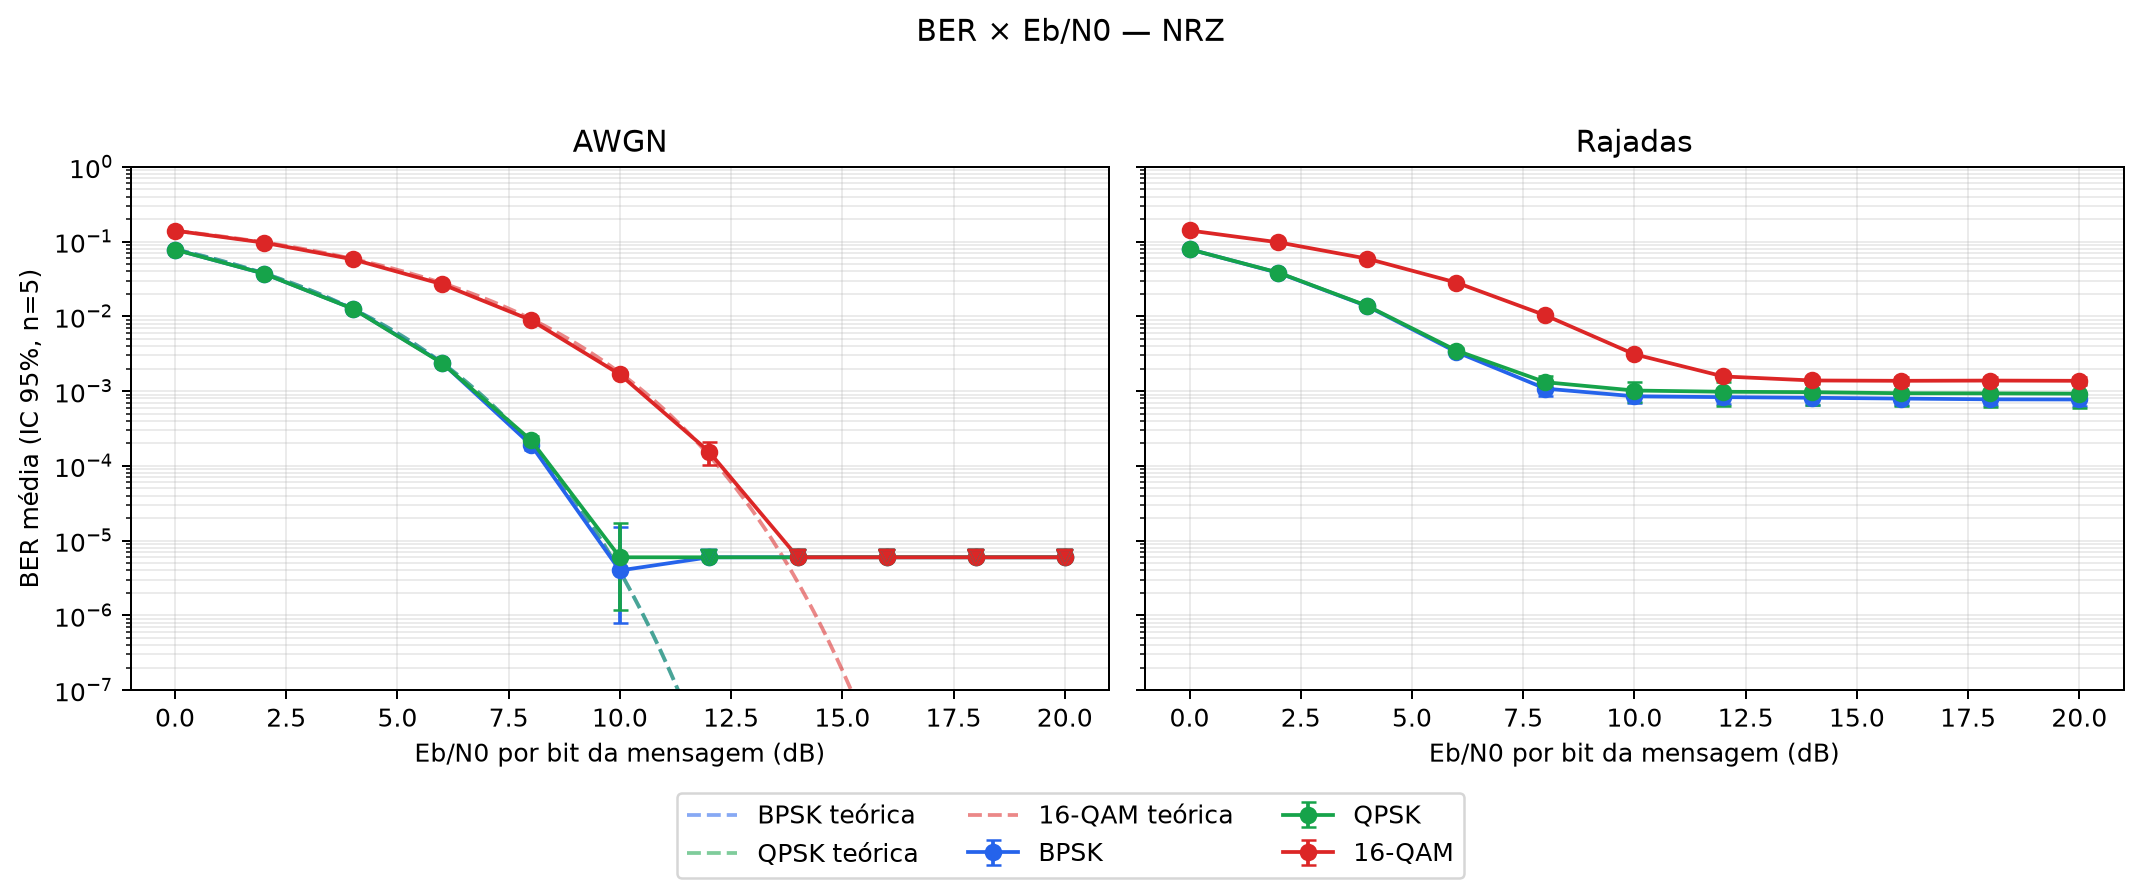

In [8]:
display(Image(filename="results/plots/ber_nrz.png", width=1100))

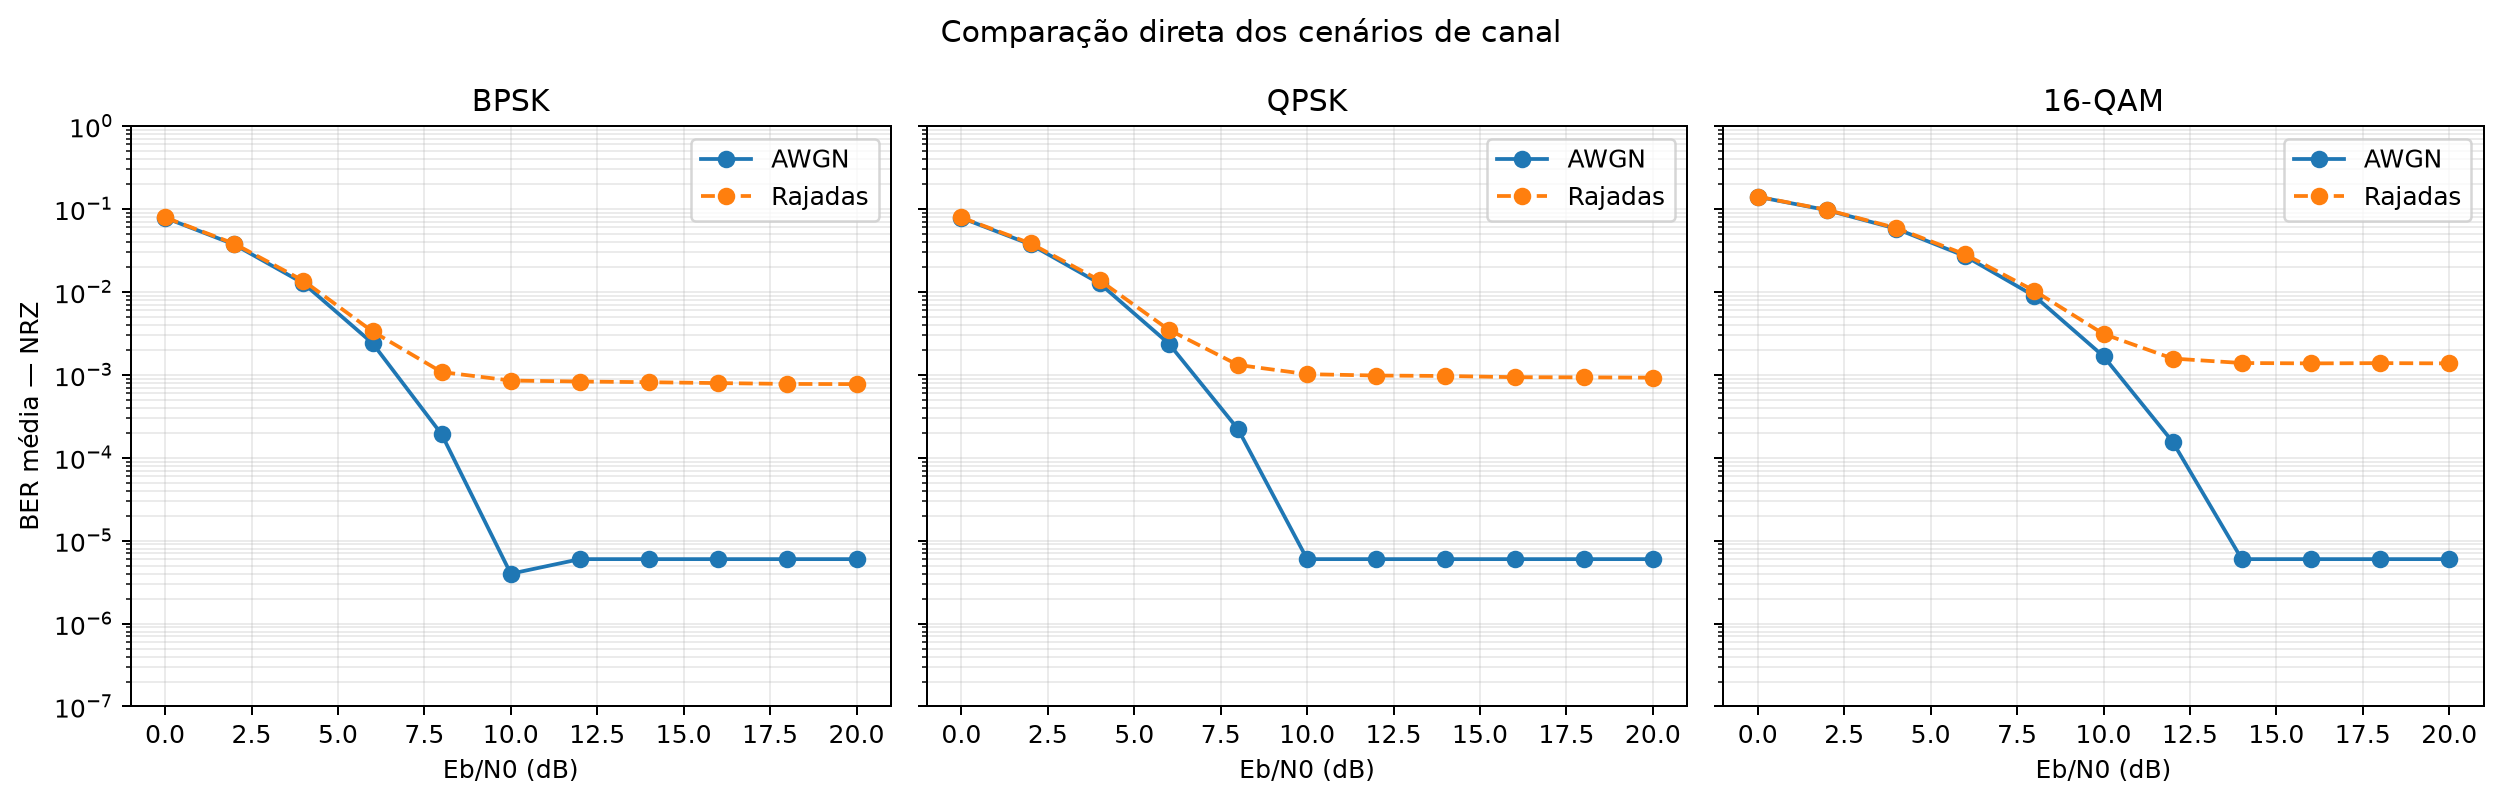

In [9]:
display(Image(filename="results/plots/comparacao_canais_nrz.png", width=1100))

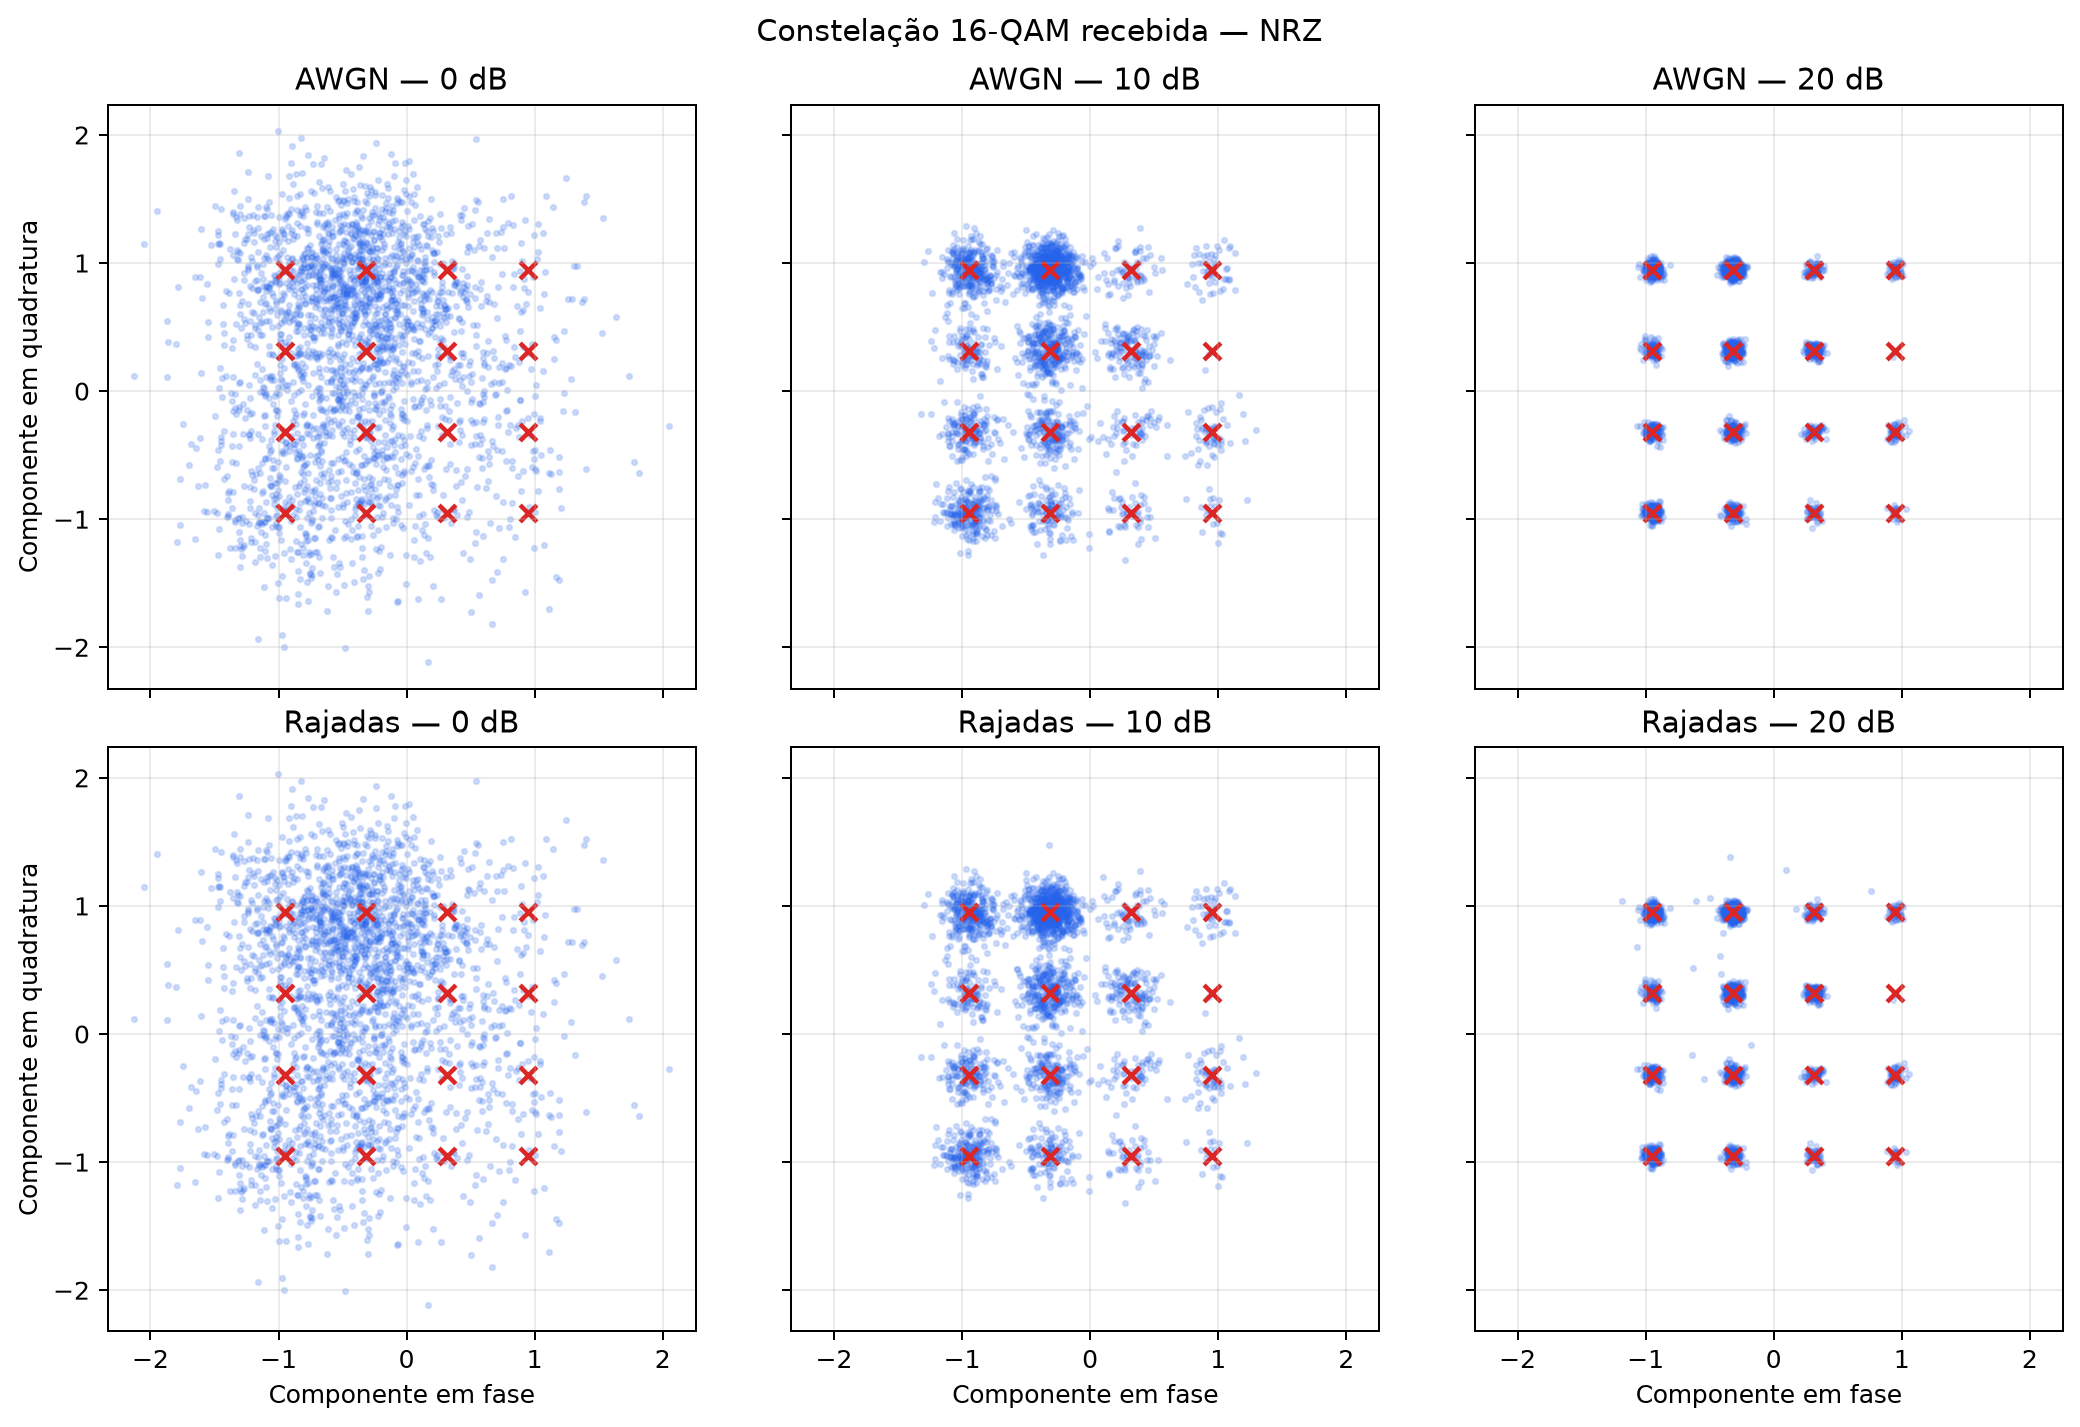

In [10]:
display(Image(filename="results/plots/constelacoes_16qam.png", width=850))

## 5. Compromisso entre BER e eficiência espectral

Eb/N0 necessário para BER = 10⁻³ em AWGN, interpolado por `make_plots.required_ebn0`.

In [11]:
labels = make_plots.LABELS
print(f"{'código':24s} {'modulação':10s} {'η (bit/s/Hz)':>13s} {'Eb/N0 p/ BER=1e-3':>18s}")
for line_code in line_codes.NAMES:
    for mod in modulation.NAMES:
        need = make_plots.required_ebn0(stats, line_code, mod, "awgn")
        need_text = f"{need:.2f} dB" if need is not None else "não atingido"
        print(f"{labels[line_code]:24s} {labels[mod]:10s} {eta_by_pair[(line_code, mod)]:13.1f} {need_text:>18s}")

código                   modulação   η (bit/s/Hz)  Eb/N0 p/ BER=1e-3
NRZ                      BPSK                 1.0            6.69 dB
NRZ                      QPSK                 2.0            6.73 dB
NRZ                      16-QAM               4.0           10.43 dB
Manchester               BPSK                 0.5            9.69 dB
Manchester               QPSK                 1.0            9.75 dB
Manchester               16-QAM               2.0           12.82 dB
Manchester diferencial   BPSK                 0.5           10.28 dB
Manchester diferencial   QPSK                 1.0           10.25 dB
Manchester diferencial   16-QAM               2.0           14.09 dB


In [12]:
display(Markdown(Path("results/tradeoff.md").read_text(encoding="utf-8")))

# Compromisso entre BER e eficiência espectral

Valores de Eb/N0 foram interpolados em escala logarítmica da BER média.

| Código | Modulação | η (bit/s/Hz) | Eb/N0 p/ BER=10⁻³ AWGN | Eb/N0 p/ BER=10⁻³ rajadas | BER AWGN @10 dB | BER rajadas @10 dB | Indicação |
|---|---:|---:|---:|---:|---:|---:|---|
| NRZ | BPSK | 1.0 | 6.69 dB | 8.64 dB | 3.99e-06 | 0.000852 | canal com pouca SNR; prioriza robustez; máxima eficiência |
| NRZ | QPSK | 2.0 | 6.73 dB | 10.90 dB | 5.98e-06 | 0.00102 | equilíbrio entre robustez e largura de banda; máxima eficiência |
| NRZ | 16-QAM | 4.0 | 10.43 dB | não atingido | 0.00167 | 0.00311 | SNR alta e largura de banda escassa; máxima eficiência |
| Manchester | BPSK | 0.5 | 9.69 dB | não atingido | 0.000718 | 0.00244 | canal com pouca SNR; prioriza robustez; sincronismo e detecção de violações |
| Manchester | QPSK | 1.0 | 9.75 dB | não atingido | 0.00077 | 0.00226 | equilíbrio entre robustez e largura de banda; sincronismo e detecção de violações |
| Manchester | 16-QAM | 2.0 | 12.82 dB | não atingido | 0.0102 | 0.0119 | SNR alta e largura de banda escassa; sincronismo e detecção de violações |
| Manchester diferencial | BPSK | 0.5 | 10.28 dB | não atingido | 0.00161 | 0.00464 | canal com pouca SNR; prioriza robustez; sincronismo e tolerância a inversão de polaridade após referência |
| Manchester diferencial | QPSK | 1.0 | 10.25 dB | não atingido | 0.00151 | 0.00406 | equilíbrio entre robustez e largura de banda; sincronismo e tolerância a inversão de polaridade após referência |
| Manchester diferencial | 16-QAM | 2.0 | 14.09 dB | não atingido | 0.0335 | 0.037 | SNR alta e largura de banda escassa; sincronismo e tolerância a inversão de polaridade após referência |


## Conclusão

- **AWGN** se combate com potência: a BER cai quando Eb/N0 sobe; BPSK e QPSK seguem a curva teórica.
- **Rajadas** criam um piso de BER que mais potência não remove.
- **16-QAM** entrega 4 bit/s/Hz com NRZ, mas exige mais Eb/N0 (≈ 10,4 dB contra ≈ 6,7 dB do BPSK para BER = 10⁻³).
- **Manchester** custa metade da eficiência espectral e cerca de 3 dB neste receptor; em troca dá sincronismo e detecção de violações.
- A escolha depende de potência disponível, largura de banda e natureza do canal.

Código, testes, dados brutos e este notebook estão no repositório do GitHub.